# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import GeoNRWDataset
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor
import imageio

## Visualize images and masks

In [35]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/GeoNRW"
}
dataset = GeoNRWDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 7689


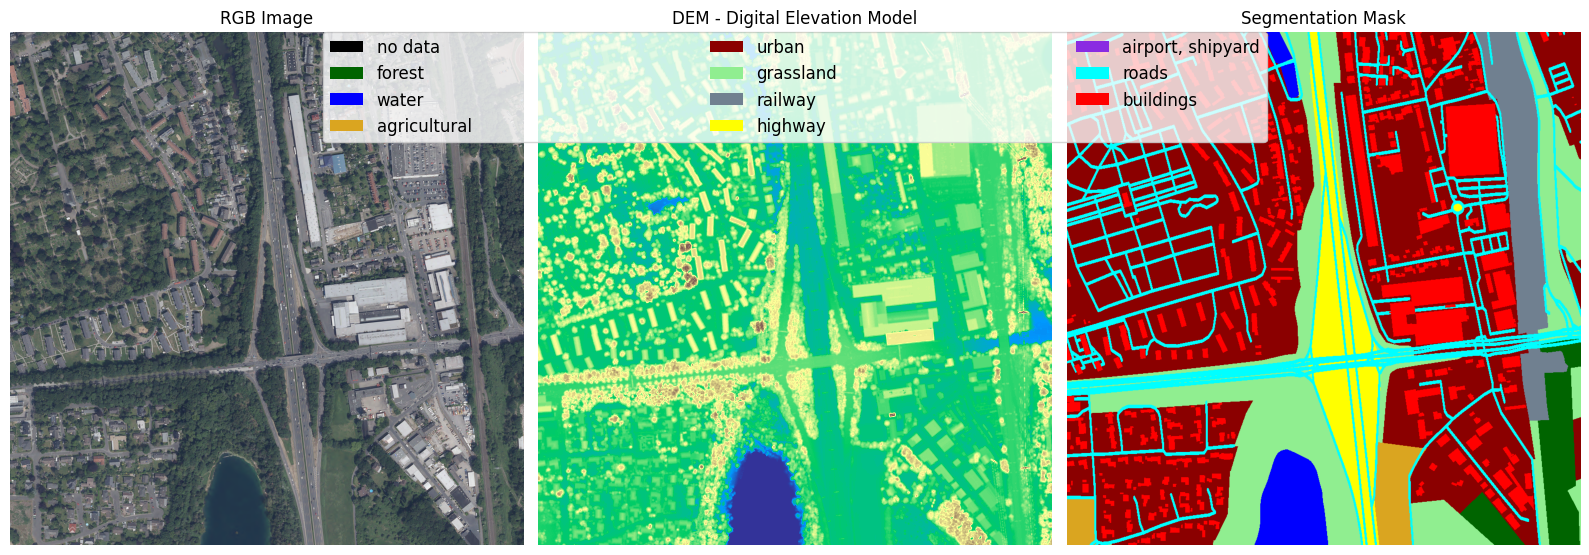

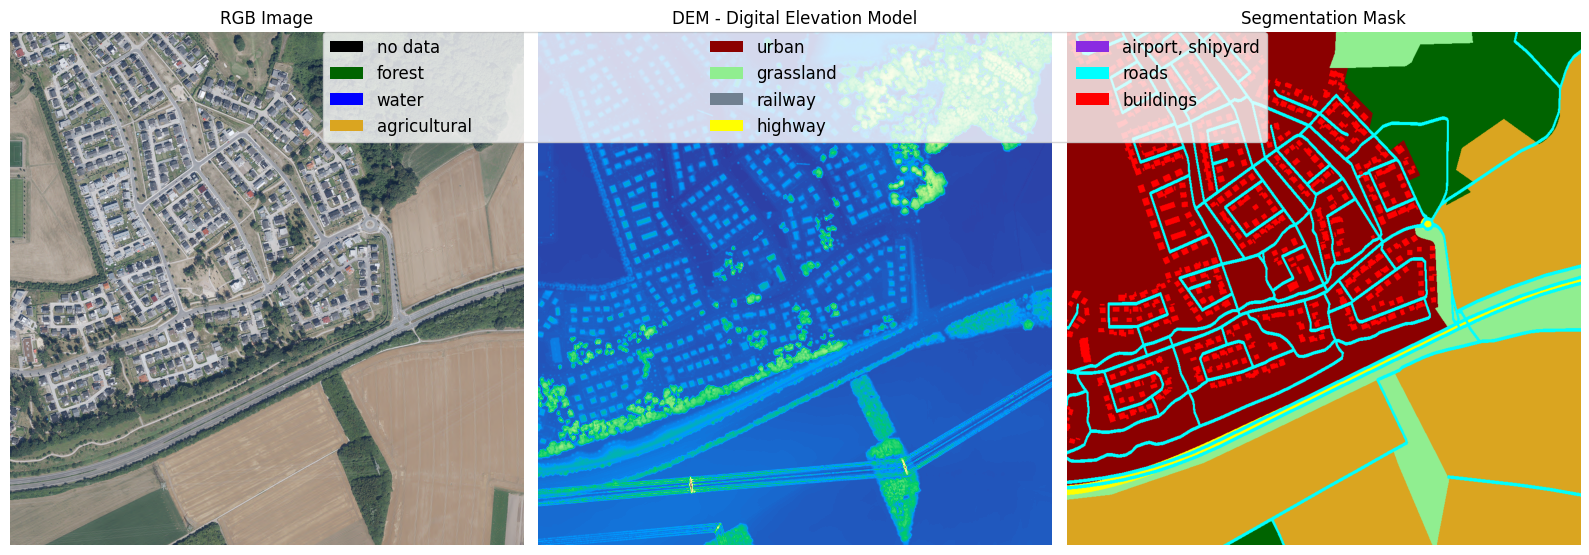

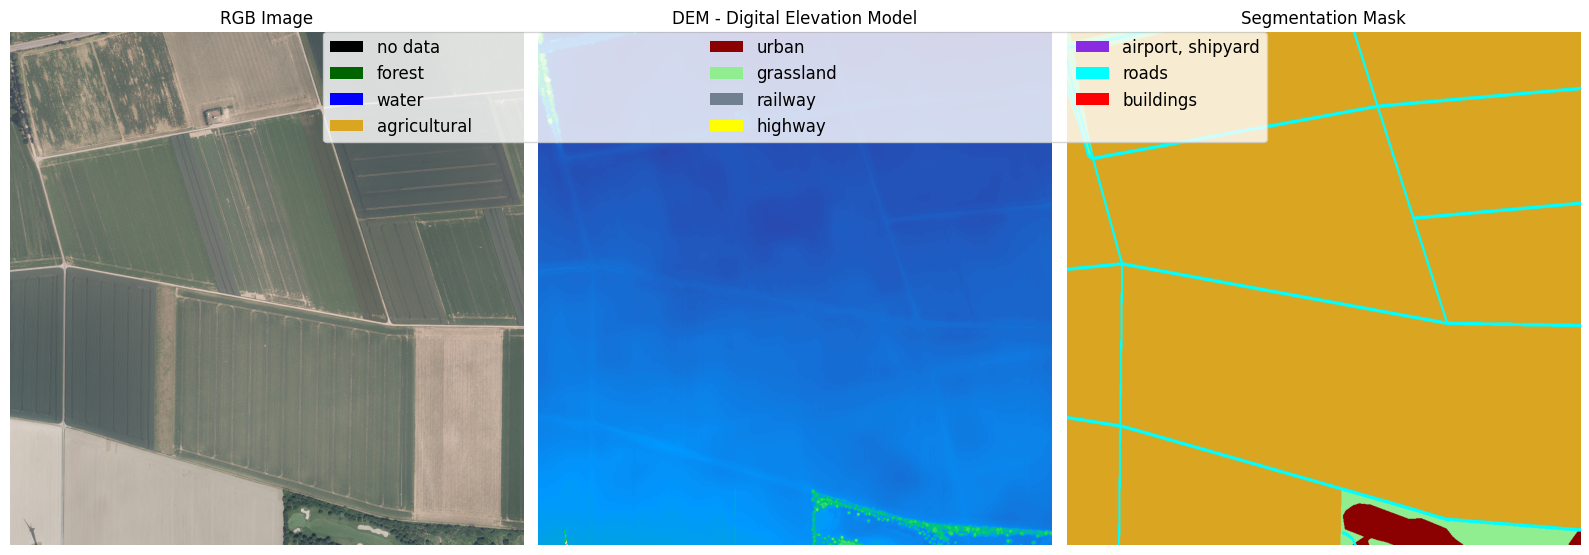

In [18]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(2040)
fig3 = dataset.show_image(7040)

In [19]:
dataset.data_distribution_table()

,Number of pixels
no data,1.460346e+08
forest,1.256436e+09
water,1.618676e+08
agricultural,2.802473e+09
urban,1.831696e+09
grassland,3.366986e+08
railway,4.273401e+07
highway,5.750586e+07
"airport, shipyard",3.477826e+07
roads,5.420532e+08


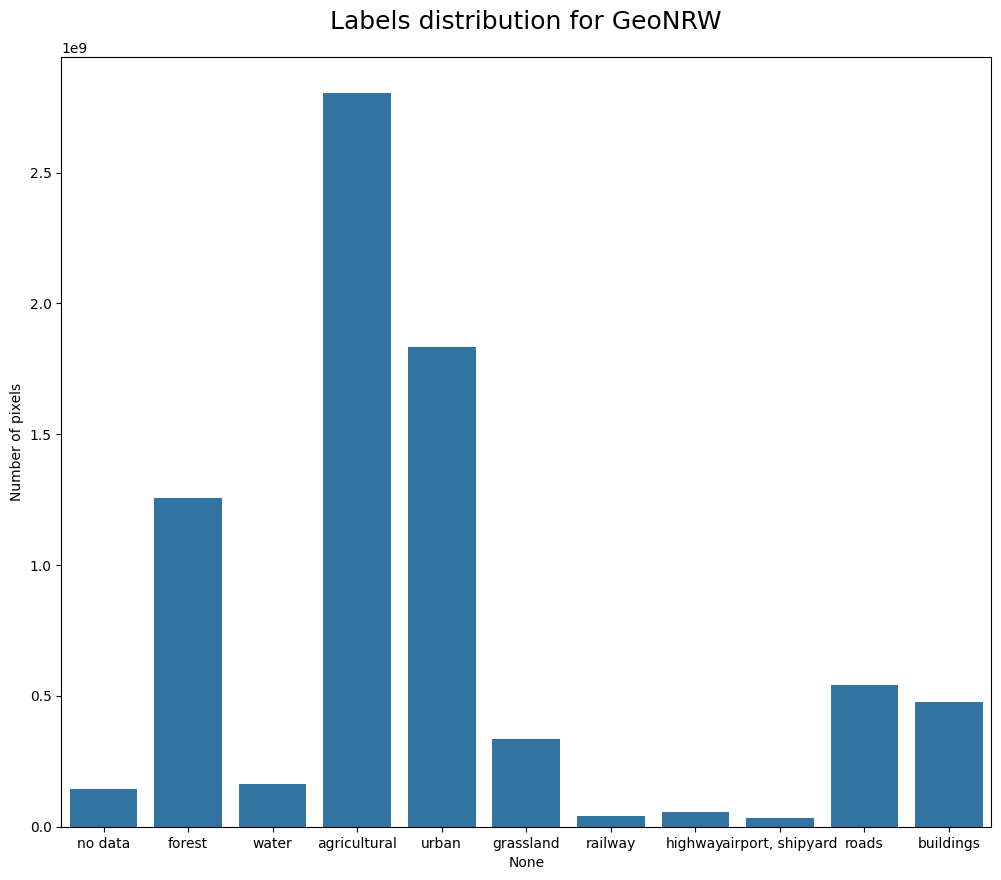

In [20]:
fig = dataset.data_distribution_barchart()

## Load training data

In [40]:
train_dataset_config = {
    "batch_size": 10,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/GeoNRW",
    "csv_file": "/home/dragik/data/FAIR_EO/GeoNRW/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = GeoNRWDataset(train_dataset_config)
len(train_dataset)

6180

## Create the model

In [41]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/GeoNRW/"
model_config = {
    "num_classes": 11, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [42]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-08-26 14:19:20,876 INFO Starting training.
training: 100%|██████████| 618/618 [10:29<00:00,  1.02s/it]
2025-08-26 14:29:50,907 INFO epoch: 1, time: 630, loss:  0.69821
testing on train set: 100%|██████████| 618/618 [10:30<00:00,  1.02s/it]
2025-08-26 14:40:23,031 INFO IOU:0.20151764325260701, IOU mean:0.05688229274946158, IOU per Class:[0.         0.14406958 0.         0.34035274 0.14128289 0.
 0.         0.         0.         0.         0.        ]
training: 100%|██████████| 618/618 [10:27<00:00,  1.02s/it]
2025-08-26 14:50:50,501 INFO epoch: 2, time: 627, loss:  0.61416
testing on train set: 100%|██████████| 618/618 [10:32<00:00,  1.02s/it]
2025-08-26 15:01:23,397 INFO IOU:0.2141521747565595, IOU mean:0.04378505795448799, IOU per Class:[0.         0.         0.         0.34035274 0.14128289 0.
 0.         0.         0.         0.         0.        ]
training: 100%|██████████| 618/618 [10:29<00:00,  1.02s/it]
2025-08-26 15:11:52,651 INFO epoch: 3, time: 629, loss:  0.60271
testin

0.5983286183628835

## Evaluate the model

In [45]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/GeoNRW",
    "csv_file": "/home/dragik/data/FAIR_EO/GeoNRW/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = GeoNRWDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/GeoNRW/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-08-27 07:13:02,506 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/GeoNRW/checkpoint.pth.tar
2025-08-27 07:13:02,845 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/GeoNRW/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 193/193 [01:21<00:00,  2.37it/s]


[{'IOU': 0.21182515995879836,
  'IOU mean': 0.0432417133818425,
  'IOU per Class': array([0.        , 0.        , 0.        , 0.32971777, 0.14594108,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        ])}]


## Predictions

2025-08-27 07:22:29,699 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/GeoNRW/checkpoint.pth.tar
2025-08-27 07:22:29,979 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/GeoNRW/checkpoint.pth.tar at epoch 11


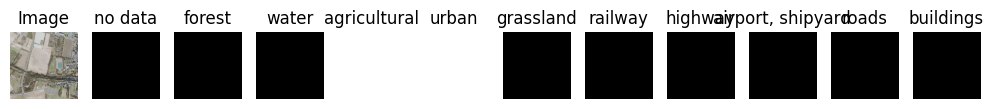

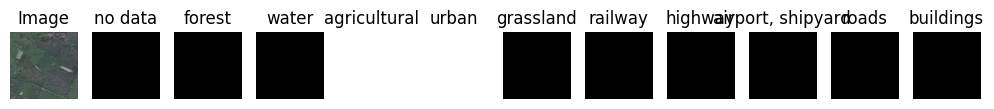

In [ ]:
model_path = "/home/dragik/data/FAIR_EO/experiments/GeoNRW/checkpoint.pth.tar"
labels = ["no data", "forest", "water", "agricultural", "urban", "grassland", "railway", "highway", "airport, shipyard", "roads", "buildings"]
transform = ResizeToTensor()
model.load_model(model_path)

image = imageio.imread("/home/dragik/data/FAIR_EO/GeoNRW/bonn/361_5622_rgb.jp2")
# image shape (H, W, 4)
if image.shape[2] == 4:
    image = image[:, :, :3]
fig = model.predict_masks(image, labels, transform)

image = imageio.imread("/home/dragik/data/FAIR_EO/GeoNRW/kleve/297_5736_rgb.jp2")
if image.shape[2] == 4:
    image = image[:, :, :3]  
fig = model.predict_masks(image, labels, transform)